# 🐸 Tadpole demo

Tadpole reads a diagram image and writes its structure. This notebook runs the downloadable model files with llama.cpp (no PyTorch, no GPU needed) and turns the answer into JSON, YAML and XML.

**You need**
- a [llama.cpp release](https://github.com/ggml-org/llama.cpp/releases), b11577 or newer: the folder that holds `llama-mtmd-cli`;
- the model files `tadpole-0.8b-Q4_K_M.gguf` and `mmproj-tadpole-0.8b-f16.gguf`;
- Python with Pillow and PyYAML. Run the notebook from the repository root.

Set the two folders below.

In [1]:
import subprocess
import sys
import time
from pathlib import Path

from IPython.display import Image, display
from PIL import Image as PILImage
from PIL import ImageDraw

sys.path.insert(0, "src")  # the diagram_ir package: output format and converters
from diagram_ir import dump, parse

LLAMA_BIN = Path("D:/data/tools/llama-b11577-cpu")  # folder with llama-mtmd-cli
MODEL_DIR = Path("D:/data/diagram_extraction/gguf/tadpole-0.8b")
MODEL = MODEL_DIR / "tadpole-0.8b-Q4_K_M.gguf"
MMPROJ = MODEL_DIR / "mmproj-tadpole-0.8b-f16.gguf"
GPU_LAYERS = 0  # 99 with a CUDA, Vulkan or Metal build of llama.cpp

## Ask Tadpole

One function: an image goes in, DGM text comes out. The prompt template is stored in the model file, and `--jinja` makes llama.cpp use it.

In [2]:
def tadpole(image, boxes=False):
    """Run Tadpole on one image and return its answer as DGM text."""
    prompt = "Convert this diagram to DGM with boxes." if boxes else "Convert this diagram to DGM."
    cmd = [str(LLAMA_BIN / "llama-mtmd-cli"), "-m", str(MODEL), "--mmproj", str(MMPROJ), "--jinja",
           "--image", str(image), "-p", prompt, "--temp", "0", "-n", "1536",
           "--image-min-tokens", "64", "--image-max-tokens", "1225", "-ngl", str(GPU_LAYERS)]
    result = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", check=True)
    return result.stdout.strip()

## 1. A hand-drawn UML activity diagram

This image is from the CAS2UML test split, so the model never saw it during training.

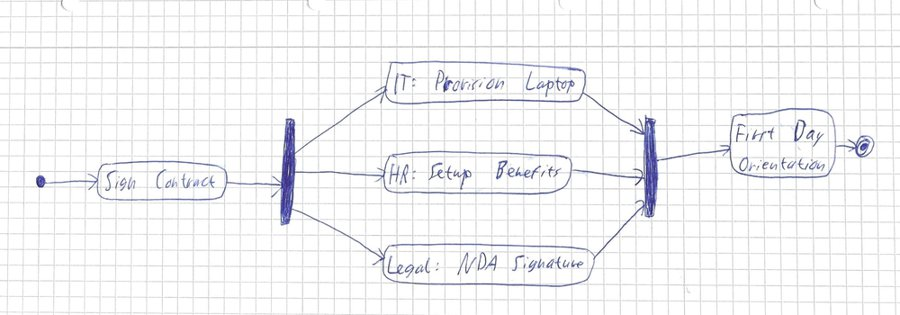

answered in 5.1 s

diagram activity dir=TB
node n1 initial
node n2 action "Sign Contract"
node n3 fork
node n4 action "IT: Provision Laptop"
node n5 action "HR: Setup Benefits"
node n6 action "Legal: NDA Signature"
node n7 join
node n8 action "First Day Orientation"
node n9 final
edge n1 n2
edge n2 n3
edge n3 n4
edge n3 n5
edge n3 n6
edge n4 n7
edge n5 n7
edge n6 n7
edge n7 n8
edge n8 n9


In [3]:
image = Path("docs/images/example_handdrawn_activity.jpg")
display(Image(filename=str(image), width=600))

start = time.time()
dgm = tadpole(image)
print(f"answered in {time.time() - start:.1f} s")
print()
print(dgm)

## 2. The same answer as JSON, YAML and XML

`parse` is lenient: if an answer were cut off, every complete line would still be kept.

In [4]:
diagram, problems = parse(dgm)
print("malformed lines:", len(problems))
print(dump(diagram, "json")[:600], "...")
print()
print(dump(diagram, "yaml")[:350], "...")
print()
print(dump(diagram, "xml")[:350], "...")

malformed lines: 0
{
  "format": "diagram-ir",
  "version": "1.0",
  "type": "activity",
  "direction": "TB",
  "nodes": [
    {
      "id": "n1",
      "kind": "initial",
      "text": ""
    },
    {
      "id": "n2",
      "kind": "action",
      "text": "Sign Contract"
    },
    {
      "id": "n3",
      "kind": "fork",
      "text": ""
    },
    {
      "id": "n4",
      "kind": "action",
      "text": "IT: Provision Laptop"
    },
    {
      "id": "n5",
      "kind": "action",
      "text": "HR: Setup Benefits"
    },
    {
      "id": "n6",
      "kind": "action",
      "text": "Legal: NDA Signature"
  ...

format: diagram-ir
version: '1.0'
type: activity
direction: TB
nodes:
- id: n1
  kind: initial
  text: ''
- id: n2
  kind: action
  text: Sign Contract
- id: n3
  kind: fork
  text: ''
- id: n4
  kind: action
  text: 'IT: Provision Laptop'
- id: n5
  kind: action
  text: 'HR: Setup Benefits'
- id: n6
  kind: action
  text: 'Legal: NDA Signature'
-  ...

<?xml version="1.0"

In [5]:
out = Path("exports")
out.mkdir(exist_ok=True)
for fmt in ("json", "yaml", "xml"):
    (out / f"activity.{fmt}").write_text(dump(diagram, fmt), encoding="utf-8")
print(sorted(p.name for p in out.iterdir()))

['activity.json', 'activity.xml', 'activity.yaml']


## 3. A photo of a hand-drawn BPMN diagram, with boxes

Asking for boxes adds `@x1,y1,x2,y2` to every element, on a 0–1000 grid over the image. Boxes were trained on BPMN and circuits. Here they are drawn back onto the photo.

diagram activity
node n1 initial "Online application\nrecieved" @117,574,144,614
node n2 action "evaluate\napplication" @302,534,430,628
node n3 decision @480,569,524,634
node n4 action "notify\ncustomer" @505,314,624,410
node n5 action "create new\nbank\naccount" @471,772,589,906
node n6 final "application\nrejected" @698,341,720,375
node n7 fork @626,809,651,853
node n8 action "send welcome\npack" @674,514,852,623
node n9 action "send bank\ncard" @685,684,828,775
node n10 action "send PIN\nnumber" @691,853,815,944
node n11 join @865,709,892,754
node n12 final "bank\naccount\ncreated" @941,709,960,744
edge n1 n2
edge n2 n3
edge n3 n4 "rejected"
edge n3 n5 "approved"
edge n4 n6
edge n4 n7
edge n5 n7
edge n7 n8
edge n7 n9
edge n7 n10
edge n8 n11
edge n9 n11
edge n10 n11
edge n11 n12


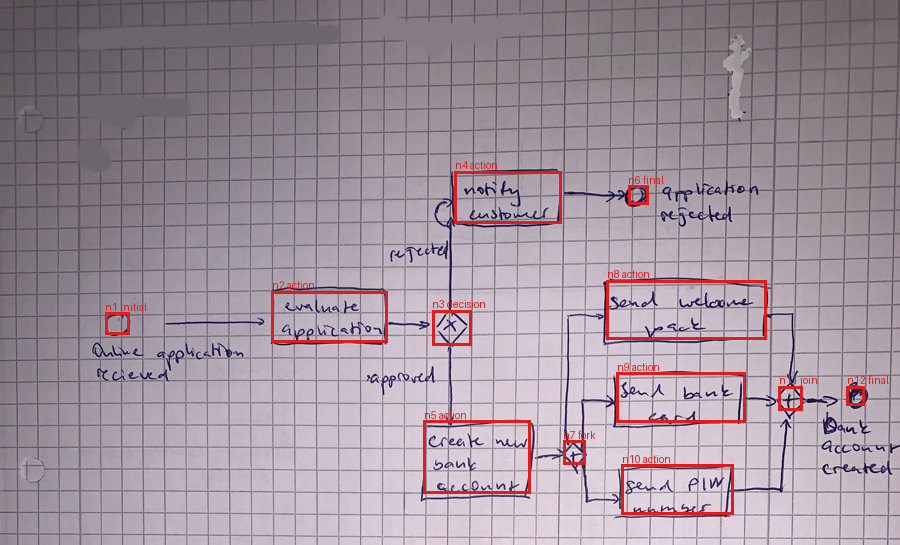

In [6]:
image = Path("docs/images/hdbpmn.jpg")
dgm = tadpole(image, boxes=True)
print(dgm)

diagram, _ = parse(dgm)
picture = PILImage.open(image).convert("RGB")
draw = ImageDraw.Draw(picture)
w, h = picture.size
for node in diagram.nodes:
    if node.bbox:
        x1, y1, x2, y2 = node.bbox
        box = (x1 * w / 1000, y1 * h / 1000, x2 * w / 1000, y2 * h / 1000)
        draw.rectangle(box, outline=(220, 30, 30), width=3)
        draw.text((box[0], max(0, box[1] - 12)), f"{node.id} {node.kind}", fill=(220, 30, 30))
display(picture)

## 4. A hand-drawn logic circuit

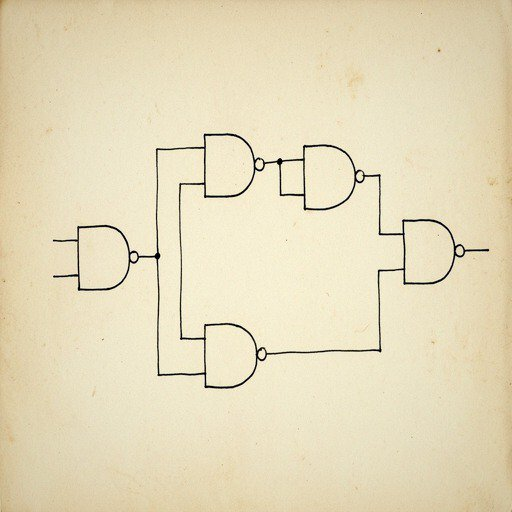

diagram circuit
node n1 nand
node n2 nand
node n3 nand
node n4 nand
node n5 nand
edge n1 n2
edge n1 n3
edge n2 n4
edge n3 n5
edge n4 n5


In [7]:
image = Path("docs/images/logicbench_1k.jpg")
display(Image(filename=str(image), width=350))
print(tadpole(image))

## With PyTorch instead

If you have the PyTorch checkpoint and a GPU, the same thing is one command:

```powershell
cd src
python -m deploy.predict ../docs/images/hdbpmn.jpg --boxes --to json
```

See the [README](README.md) for downloads, and the [output format](src/diagram_ir/SPEC.md) for what every line means.